# Inversor CMOS gf180mcuD — Análisis LTspice
Lectura y graficación de resultados de LTspice usando `spicelib`, `matplotlib`, `prettytable` y `si_prefix`.

Archivos usados en este notebook:
- `op` → `inv_op.log`
- `dc` → `inv_dc.raw`
- `tran` → `inv_tran.raw`
- `ac` → `inv_ac.raw`
- `noise` → `inv_noise.raw`

## 1. Imports
Se cargan una sola vez, se usan en todas las secciones siguientes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import EngFormatter, LogLocator, NullFormatter

from spicelib import RawRead
from spicelib.log.semi_dev_op_reader import opLogReader

from prettytable import PrettyTable
from si_prefix import si_format as num2eng

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

# numpy renombro trapz -> trapezoid en versiones recientes; esto funciona con ambas
trapz = getattr(np, "trapezoid", None) or np.trapz


## 2. Funciones auxiliares
Formato de ejes con prefijos de ingeniería (n, u, k, M, G...), respetando tamaño/peso de fuente de los ticks en ambos ejes.

In [2]:
def format_loglog_axes(ax, y_unit="", labelsize=14, weight="normal"):
    """Aplica formato de prefijos de ingenieria a un par de ejes log-log
    (usar en graficas donde tanto X como Y estan en escala logaritmica,
    ej. espectros de ruido)."""
    ax.xaxis.set_major_formatter(EngFormatter(unit="Hz"))
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 3, 5, 7), numticks=20))
    ax.yaxis.set_major_formatter(EngFormatter(unit=y_unit))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.tick_params(axis="both", which="major", labelsize=labelsize)
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontweight(weight)


def format_freq_axis(ax, labelsize=14, weight="normal"):
    """Aplica formato de prefijos de ingenieria al eje de frecuencia (X)
    y unifica tamano/peso de fuente en ambos ejes (X y Y). Usar en graficas
    semilogx, ej. Bode con ganancia en dB / fase en grados.

    IMPORTANTE en graficas con doble eje Y (twinx): llamar esta funcion
    DESPUES de graficar en ambos ejes (ax1 y ax2). twinx() comparte el
    mismo XAxis entre ambos ejes, y cualquier semilogx/set_xscale posterior
    (incluido el de ax2) resetea el formatter del eje X compartido a su
    default. Si se llama antes, el EngFormatter se pierde."""
    ax.xaxis.set_major_formatter(EngFormatter(unit="Hz"))
    ax.tick_params(axis="both", which="major", labelsize=labelsize)
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontweight(weight)


## 3. Punto de operación (`.op`)

Lee `inv_op.log` y muestra el punto de operación de cada transistor en una tabla (filas = parámetros, columnas = transistores).

In [3]:
LOG_LTSPICE = r"inv_op.log"

op_data = opLogReader(LOG_LTSPICE)
mosfets = op_data["bsim4 mosfets"]

devices = list(mosfets.keys())
params  = ["Id", "Vgs", "Vds", "Vbs", "Vth", "Vdsat",
           "Gm", "Gds", "Gmb", "Cbd", "Cbs"]

table = PrettyTable()
table.field_names = ["Parámetro"] + devices

for p in params:
    row = [p]
    for dev in devices:
        row.append(num2eng(mosfets[dev][p]))
    table.add_row(row)

print(f"Punto de operación — {LOG_LTSPICE}\n")
print(table)


Punto de operación — inv_op.log

+-----------+----------+----------+
| Parámetro | u0:x1:m0 | u1:x1:m0 |
+-----------+----------+----------+
|     Id    | 119.0 µ  | -119.0 µ |
|    Vgs    |   1.6    |  -1.6    |
|    Vds    | 438.0 m  |  -2.9    |
|    Vbs    |   0.0    |   0.0    |
|    Vth    | 699.0 m  | -789.0 m |
|   Vdsat   | 717.0 m  | -703.0 m |
|     Gm    | 139.0 µ  | 245.0 µ  |
|    Gds    | 162.0 µ  |  1.8 µ   |
|    Gmb    |  56.0 µ  | 111.0 µ  |
|    Cbd    |  1.7 f   |  3.5 f   |
|    Cbs    |  1.9 f   |  4.9 f   |
+-----------+----------+----------+


## 4. DC Sweep
Curva de transferencia (VOUT), ganancia, corriente de drenador y transconductancia (gm) de U1.

In [7]:
RAW_LTSPICE_DC = r"inv_dc.raw"

raw_dc = RawRead(RAW_LTSPICE_DC)

vin_dc   = raw_dc.get_trace("V3").get_wave()
vout_dc  = raw_dc.get_trace("V(vout)").get_wave()
id_u1_dc = raw_dc.get_trace("Ix(u1:d)").get_wave()

# gm = dID/dVGS ; VGS(U1)=VIN, pero VDS(U1)=VOUT tambien varia en este barrido,
# asi que esta gm mezcla el efecto de VGS y VDS a lo largo de la curva de conmutacion.
gm_u1_dc = np.gradient(id_u1_dc, vin_dc)
gain_dc  = np.gradient(vout_dc, vin_dc)


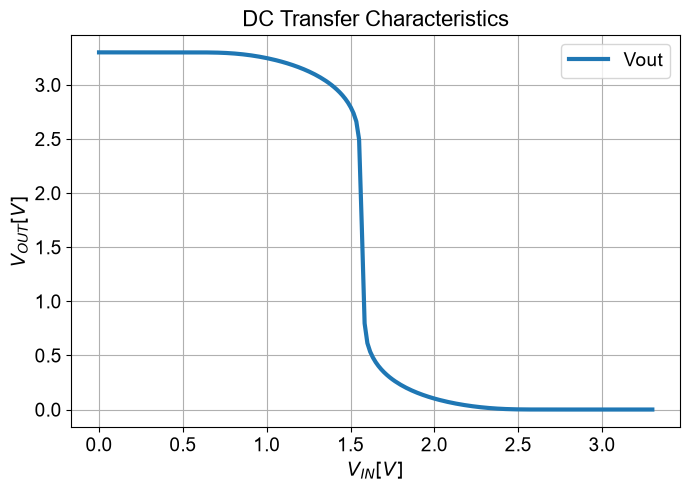

In [8]:
plt.figure(figsize=(7, 5))
plt.plot(vin_dc, vout_dc, linewidth=3, label='Vout')
plt.legend(prop={"size": 14, 'weight': 'normal'}, loc="upper right")
plt.title('DC Transfer Characteristics', weight='normal', fontsize=16)
plt.xlabel(r'$V_{IN} [V]$', weight='normal', fontsize=14)
plt.ylabel(r'$V_{OUT} [V]$', weight='normal', fontsize=14)
plt.xticks(weight='normal', fontsize=14)
plt.yticks(weight='normal', fontsize=14)
plt.grid()
plt.tight_layout()
plt.show()


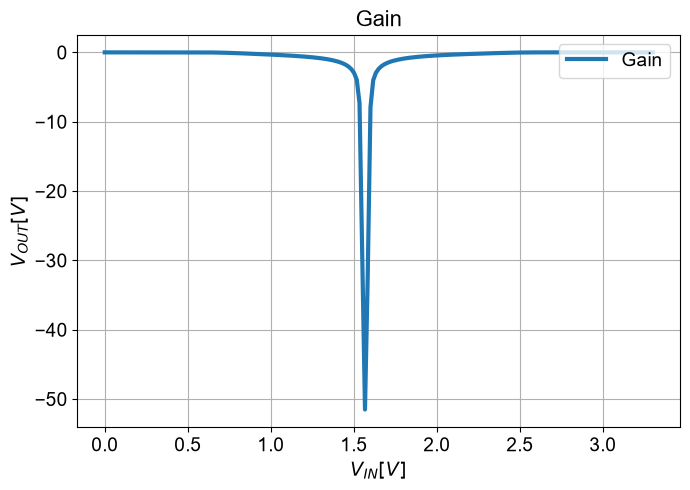

In [9]:
plt.figure(figsize=(7, 5))
plt.plot(vin_dc, gain_dc, linewidth=3, label='Gain')
plt.legend(prop={"size": 14, 'weight': 'normal'}, loc="upper right")
plt.title('Gain', weight='normal', fontsize=16)
plt.xlabel(r'$V_{IN} [V]$', weight='normal', fontsize=14)
plt.ylabel(r'$V_{OUT} [V]$', weight='normal', fontsize=14)
plt.xticks(weight='normal', fontsize=14)
plt.yticks(weight='normal', fontsize=14)
plt.grid()
plt.tight_layout()
plt.show()


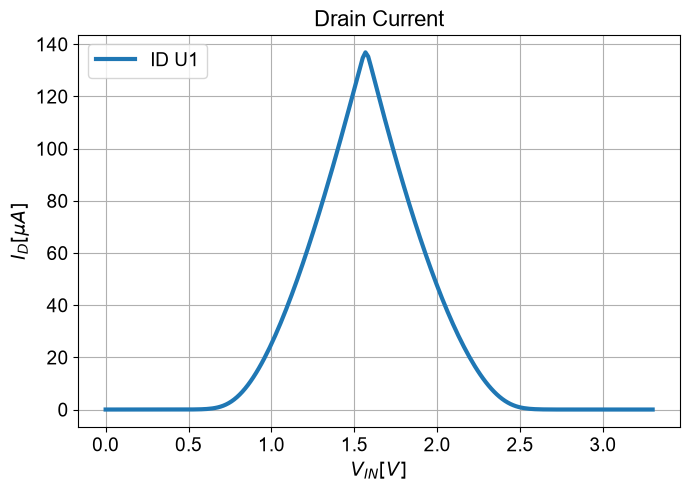

In [10]:
plt.figure(figsize=(7, 5))
plt.plot(vin_dc, id_u1_dc * 1e6, linewidth=3, label='ID U1')
plt.legend(prop={"size": 14, 'weight': 'normal'}, loc="upper left")
plt.title('Drain Current', weight='normal', fontsize=16)
plt.xlabel(r'$V_{IN} [V]$', weight='normal', fontsize=14)
plt.ylabel(r'$I_{D} [\mu A]$', weight='normal', fontsize=14)
plt.xticks(weight='normal', fontsize=14)
plt.yticks(weight='normal', fontsize=14)
plt.grid()
plt.tight_layout()
plt.show()


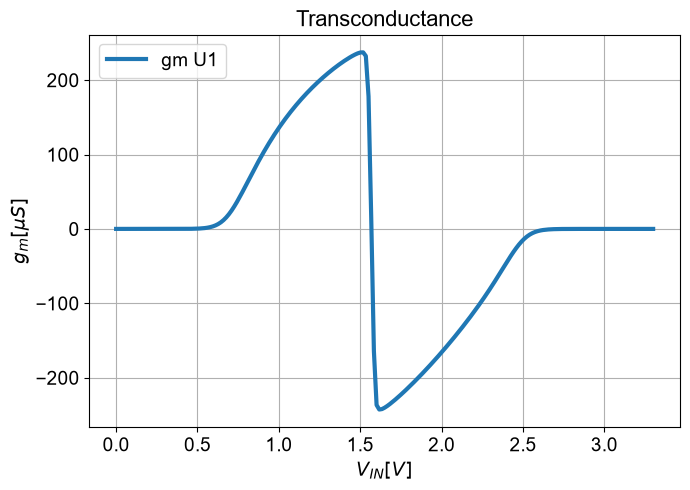

In [11]:
plt.figure(figsize=(7, 5))
plt.plot(vin_dc, gm_u1_dc * 1e6, linewidth=3, label='gm U1')
plt.legend(prop={"size": 14, 'weight': 'normal'}, loc="upper left")
plt.title('Transconductance', weight='normal', fontsize=16)
plt.xlabel(r'$V_{IN} [V]$', weight='normal', fontsize=14)
plt.ylabel(r'$g_m [\mu S]$', weight='normal', fontsize=14)
plt.xticks(weight='normal', fontsize=14)
plt.yticks(weight='normal', fontsize=14)
plt.grid()
plt.tight_layout()
plt.show()


## 5. Transitorio
Gráfica 1: Vin y Vout superpuestos. Gráfica 2: Vin y Vout en subplots apilados (eje X compartido).

In [12]:
RAW_LTSPICE_TRAN = r"inv_tran.raw"

raw_tran = RawRead(RAW_LTSPICE_TRAN)
t_tran    = raw_tran.get_trace("time").get_wave()
vin_tran  = raw_tran.get_trace("V(vin)").get_wave()
vout_tran = raw_tran.get_trace("V(vout)").get_wave()

t_ns_tran = t_tran * 1e9   # tiempo en ns para que los ejes sean mas legibles


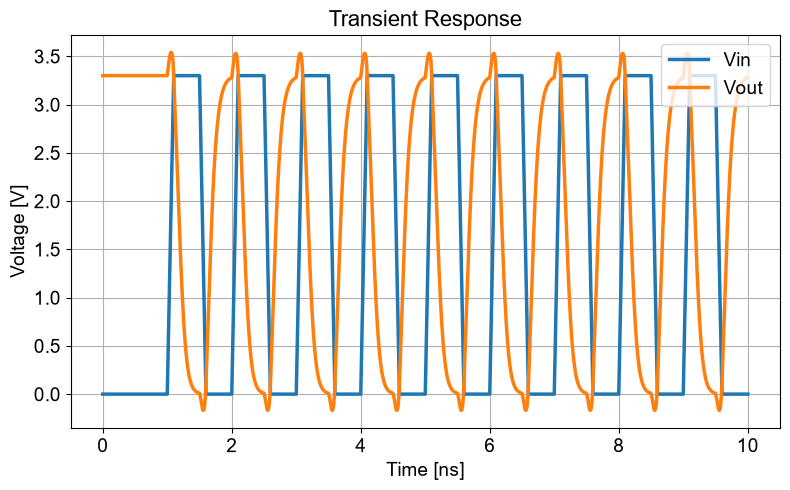

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(t_ns_tran, vin_tran, linewidth=2.5, label='Vin')
plt.plot(t_ns_tran, vout_tran, linewidth=2.5, label='Vout')
plt.legend(prop={"size": 14, 'weight': 'normal'}, loc="upper right")
plt.title('Transient Response', weight='normal', fontsize=16)
plt.xlabel('Time [ns]', weight='normal', fontsize=14)
plt.ylabel('Voltage [V]', weight='normal', fontsize=14)
plt.xticks(weight='normal', fontsize=14)
plt.yticks(weight='normal', fontsize=14)
plt.grid(True)
plt.tight_layout()
plt.show()


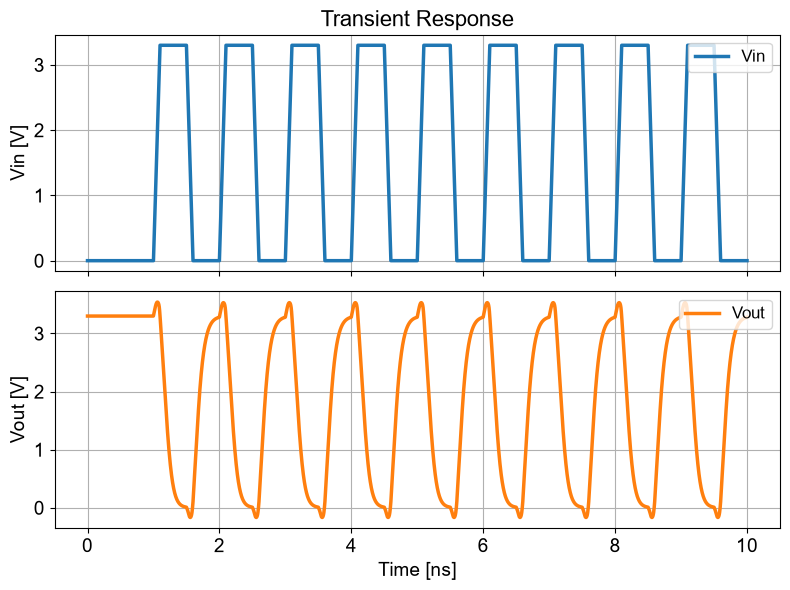

In [14]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

ax1.plot(t_ns_tran, vin_tran, linewidth=2.5, color='tab:blue', label='Vin')
ax1.set_ylabel('Vin [V]', weight='normal', fontsize=14)
ax1.legend(prop={"size": 12}, loc="upper right")
ax1.grid(True)
ax1.set_title('Transient Response', weight='normal', fontsize=16)

ax2.plot(t_ns_tran, vout_tran, linewidth=2.5, color='tab:orange', label='Vout')
ax2.set_ylabel('Vout [V]', weight='normal', fontsize=14)
ax2.set_xlabel('Time [ns]', weight='normal', fontsize=14)
ax2.legend(prop={"size": 12}, loc="upper right")
ax2.grid(True)

# --- estilo de ticks aplicado a AMBOS ejes explícitamente ---
for ax in (ax1, ax2):
    ax.tick_params(axis="both", which="major", labelsize=14)
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontweight("normal")

plt.tight_layout()
plt.show()

## 6. AC / Bode
Ganancia en dB, fase en grados, y ambas con doble eje Y. Métricas: ganancia a baja frecuencia, ancho de banda, frecuencia de ganancia unitaria y fase en ese cruce.

In [15]:
RAW_LTSPICE_AC = r"inv_ac.raw"

raw_ac = RawRead(RAW_LTSPICE_AC)
freq_ac = np.abs(raw_ac.get_trace("frequency").get_wave())
vout_ac = raw_ac.get_trace("V(vout)").get_wave()

gain_db_ac   = 20 * np.log10(np.abs(vout_ac))
phase_deg_ac = np.angle(vout_ac, deg=True)


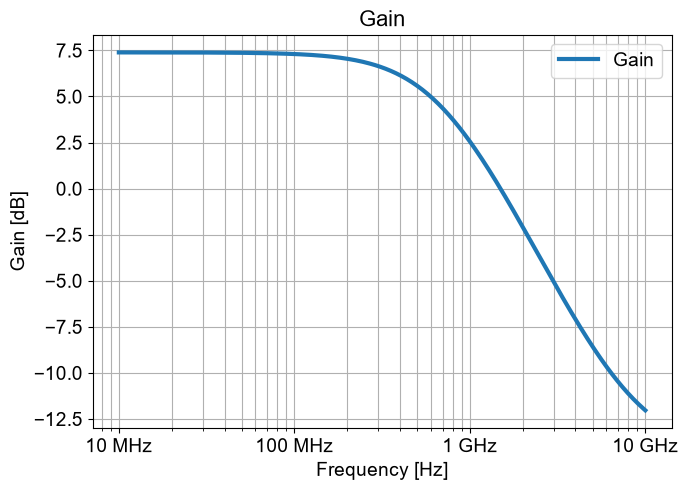

In [16]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogx(freq_ac, gain_db_ac, linewidth=3, label="Gain")
ax.legend(prop={"size": 14, "weight": "normal"}, loc="upper right")
ax.set_title("Gain", weight="normal", fontsize=16)
ax.set_xlabel("Frequency [Hz]", weight="normal", fontsize=14)
ax.set_ylabel("Gain [dB]", weight="normal", fontsize=14)
format_freq_axis(ax)
ax.grid(True, which="both")
plt.tight_layout()
plt.show()


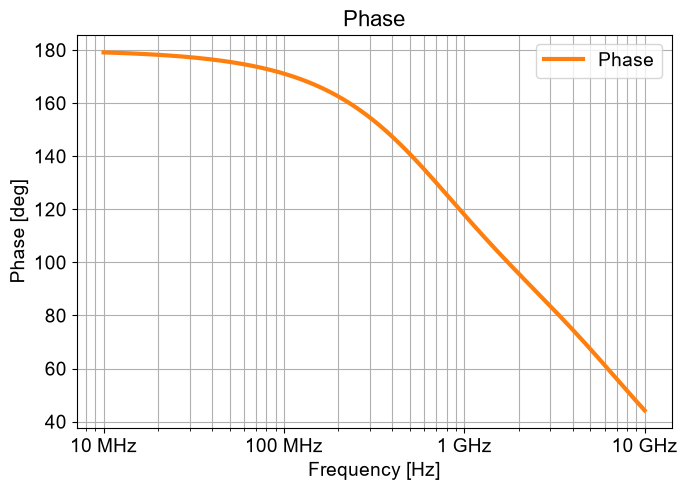

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogx(freq_ac, phase_deg_ac, linewidth=3, color="tab:orange", label="Phase")
ax.legend(prop={"size": 14, "weight": "normal"}, loc="upper right")
ax.set_title("Phase", weight="normal", fontsize=16)
ax.set_xlabel("Frequency [Hz]", weight="normal", fontsize=14)
ax.set_ylabel("Phase [deg]", weight="normal", fontsize=14)
format_freq_axis(ax)
ax.grid(True, which="both")
plt.tight_layout()
plt.show()


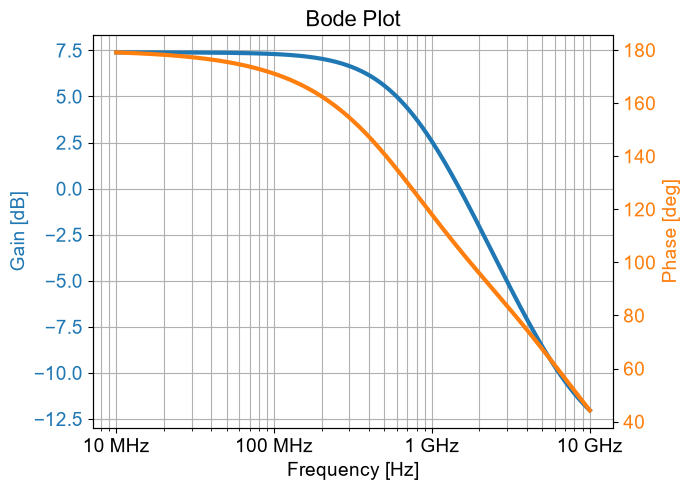

In [18]:
fig, ax1 = plt.subplots(figsize=(7, 5))

color1 = "tab:blue"
ax1.semilogx(freq_ac, gain_db_ac, linewidth=3, color=color1, label="Gain")
ax1.set_xlabel("Frequency [Hz]", weight="normal", fontsize=14)
ax1.set_ylabel("Gain [dB]", weight="normal", fontsize=14, color=color1)
ax1.tick_params(axis="y", labelcolor=color1, labelsize=14)
ax1.grid(True, which="both")

ax2 = ax1.twinx()
color2 = "tab:orange"
ax2.semilogx(freq_ac, phase_deg_ac, linewidth=3, color=color2, label="Phase")
ax2.set_ylabel("Phase [deg]", weight="normal", fontsize=14, color=color2)
ax2.tick_params(axis="y", labelcolor=color2, labelsize=14)

# format_freq_axis se llama AL FINAL, despues de graficar en ax1 y ax2:
# twinx() comparte el mismo eje X entre ambos ejes, y el semilogx de ax2
# resetea el formatter si se llama antes.
format_freq_axis(ax1)

plt.title("Bode Plot", weight="normal", fontsize=16)
fig.tight_layout()
plt.show()


In [19]:
# --- Metricas ---
low_freq_gain_db = gain_db_ac[0]

target_bw = low_freq_gain_db - 3
idx_bw = np.where(gain_db_ac <= target_bw)[0][0]
bandwidth = np.exp(np.interp(
    target_bw,
    [gain_db_ac[idx_bw - 1], gain_db_ac[idx_bw]],
    [np.log(freq_ac[idx_bw - 1]), np.log(freq_ac[idx_bw])],
))

idx_ug = np.where(gain_db_ac <= 0)[0][0]
f_unity = np.exp(np.interp(
    0,
    [gain_db_ac[idx_ug - 1], gain_db_ac[idx_ug]],
    [np.log(freq_ac[idx_ug - 1]), np.log(freq_ac[idx_ug])],
))
phase_at_unity = np.interp(
    np.log(f_unity),
    [np.log(freq_ac[idx_ug - 1]), np.log(freq_ac[idx_ug])],
    [phase_deg_ac[idx_ug - 1], phase_deg_ac[idx_ug]],
)

table = PrettyTable()
table.field_names = ["Métrica", "Valor"]
table.add_row(["Ganancia a baja frecuencia", f"{low_freq_gain_db:.2f} dB"])
table.add_row(["Ancho de banda (-3dB)", num2eng(bandwidth) + "Hz"])
table.add_row(["Frecuencia de ganancia unitaria", num2eng(f_unity) + "Hz"])
table.add_row(["Fase en ganancia unitaria", f"{phase_at_unity:.2f} deg"])

print(table)


+---------------------------------+------------+
|             Métrica             |   Valor    |
+---------------------------------+------------+
|    Ganancia a baja frecuencia   |  7.39 dB   |
|      Ancho de banda (-3dB)      | 707.9 MHz  |
| Frecuencia de ganancia unitaria |  1.5 GHz   |
|    Fase en ganancia unitaria    | 104.46 deg |
+---------------------------------+------------+


## 7. Ruido
Espectros de `inoise`, `onoise`, y componentes de ruido de U1 (Id, 1/f, total). Métricas: valores puntuales a una frecuencia de referencia, ganancia onoise/inoise, frecuencia de esquina de flicker de U1, piso de ruido blanco y ruido RMS integrado.

In [20]:
RAW_LTSPICE_NOISE = r"inv_noise.raw"
F_REPORT = 1e6   # frecuencia de referencia para el reporte puntual (ajustable)

raw_noise = RawRead(RAW_LTSPICE_NOISE)
f_noise      = np.abs(raw_noise.get_trace("frequency").get_wave())
onoise_noise = np.abs(raw_noise.get_trace("v(onoise)").get_wave())
inoise_noise = np.abs(raw_noise.get_trace("v(inoise)").get_wave())
id_u1_noise  = np.abs(raw_noise.get_trace("v(u1:x1:m0.id)").get_wave())
f1_u1_noise  = np.abs(raw_noise.get_trace("v(u1:x1:m0.1overf)").get_wave())
tot_u1_noise = np.abs(raw_noise.get_trace("v(u1:x1:m0)").get_wave())


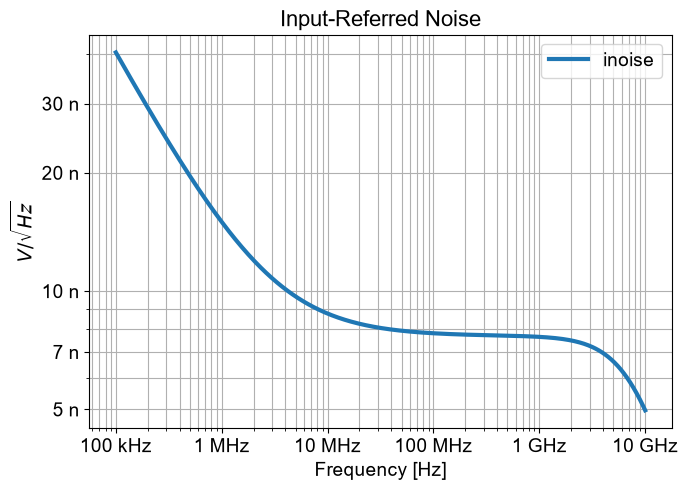

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(f_noise, inoise_noise, linewidth=3, label="inoise")
ax.legend(prop={"size": 14}, loc="upper right")
ax.set_title("Input-Referred Noise", fontsize=16)
ax.set_xlabel("Frequency [Hz]", fontsize=14)
ax.set_ylabel(r"$V/\sqrt{Hz}$", fontsize=14)
format_loglog_axes(ax)
ax.grid(True, which="both")
plt.tight_layout()
plt.show()


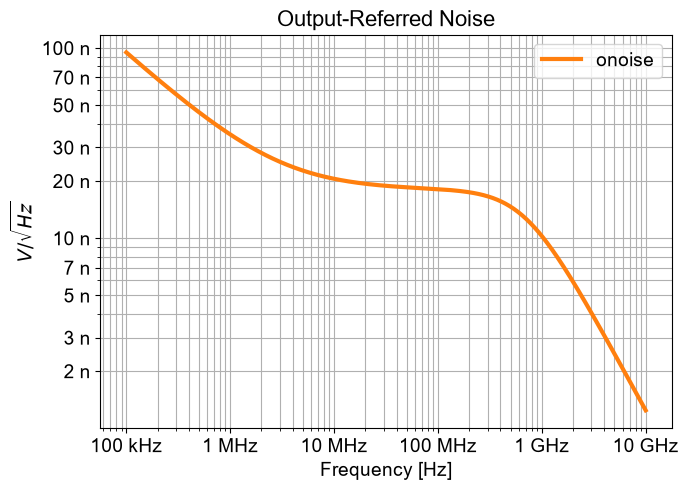

In [22]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(f_noise, onoise_noise, linewidth=3, color="tab:orange", label="onoise")
ax.legend(prop={"size": 14}, loc="upper right")
ax.set_title("Output-Referred Noise", fontsize=16)
ax.set_xlabel("Frequency [Hz]", fontsize=14)
ax.set_ylabel(r"$V/\sqrt{Hz}$", fontsize=14)
format_loglog_axes(ax)
ax.grid(True, which="both")
plt.tight_layout()
plt.show()


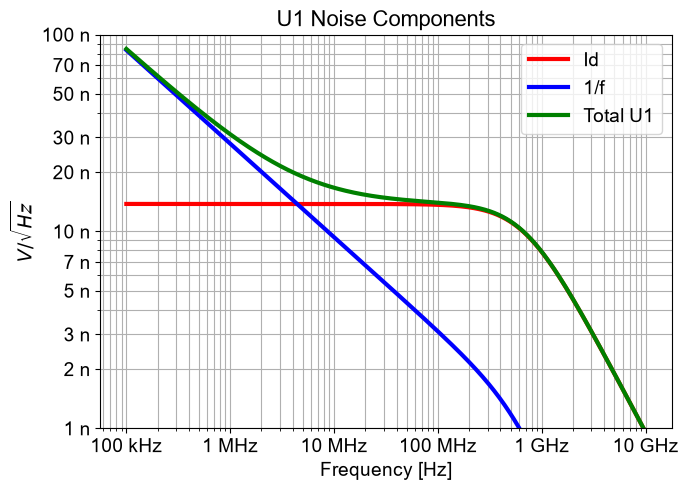

In [23]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(f_noise, id_u1_noise, linewidth=3, color="red", label="Id")
ax.loglog(f_noise, f1_u1_noise, linewidth=3, color="blue", label="1/f")
ax.loglog(f_noise, tot_u1_noise, linewidth=3, color="green", label="Total U1")
ax.legend(prop={"size": 14}, loc="upper right")
ax.set_title("U1 Noise Components", fontsize=16)
ax.set_xlabel("Frequency [Hz]", fontsize=14)
ax.set_ylabel(r"$V/\sqrt{Hz}$", fontsize=14)
format_loglog_axes(ax)
ax.grid(True, which="both")
plt.ylim(1e-9, 100e-9)
plt.tight_layout()
plt.show()


In [24]:
# --- Metricas ---
onoise_at_f = np.interp(np.log10(F_REPORT), np.log10(f_noise), onoise_noise)
inoise_at_f = np.interp(np.log10(F_REPORT), np.log10(f_noise), inoise_noise)
gain_at_f = onoise_at_f / inoise_at_f   # onoise/inoise = |ganancia| del circuito

# frecuencia de esquina de flicker de U1: donde 1/f cruza a id
diff = f1_u1_noise - id_u1_noise
cross_idx = np.where(np.diff(np.sign(diff)))[0]
if len(cross_idx) > 0:
    idx = cross_idx[0]
    f_corner = np.exp(np.interp(0, [diff[idx], diff[idx + 1]],
                                 [np.log(f_noise[idx]), np.log(f_noise[idx + 1])]))
else:
    f_corner = np.nan

# piso de ruido blanco: promedio de los ultimos puntos (alta frecuencia)
onoise_floor = np.mean(onoise_noise[-20:])
inoise_floor = np.mean(inoise_noise[-20:])

# ruido RMS integrado sobre toda la banda simulada:
# RMS = sqrt( integral( PSD(f)^2 df ) ), PSD en V/sqrt(Hz) -> RMS en V
onoise_rms = np.sqrt(trapz(onoise_noise**2, f_noise))
inoise_rms = np.sqrt(trapz(inoise_noise**2, f_noise))

table = PrettyTable()
table.field_names = ["Métrica", "Valor"]
table.add_row([f"Onoise @ {num2eng(F_REPORT)}Hz", num2eng(onoise_at_f) + "V/sqrt(Hz)"])
table.add_row([f"Inoise @ {num2eng(F_REPORT)}Hz", num2eng(inoise_at_f) + "V/sqrt(Hz)"])
table.add_row([f"Gain (onoise/inoise) @ {num2eng(F_REPORT)}Hz", f"{gain_at_f:.3f}"])
table.add_row(["U1 flicker corner freq", num2eng(f_corner) + "Hz"])
table.add_row(["Onoise white floor", num2eng(onoise_floor) + "V/sqrt(Hz)"])
table.add_row(["Inoise white floor", num2eng(inoise_floor) + "V/sqrt(Hz)"])
table.add_row([f"Onoise RMS ({num2eng(f_noise[0])}Hz-{num2eng(f_noise[-1])}Hz)", num2eng(onoise_rms) + "V"])
table.add_row([f"Inoise RMS ({num2eng(f_noise[0])}Hz-{num2eng(f_noise[-1])}Hz)", num2eng(inoise_rms) + "V"])

print(table)


+---------------------------------+------------------+
|             Métrica             |      Valor       |
+---------------------------------+------------------+
|         Onoise @ 1.0 MHz        | 35.1 nV/sqrt(Hz) |
|         Inoise @ 1.0 MHz        | 15.0 nV/sqrt(Hz) |
|  Gain (onoise/inoise) @ 1.0 MHz |      2.342       |
|      U1 flicker corner freq     |     4.5 MHz      |
|        Onoise white floor       | 1.6 nV/sqrt(Hz)  |
|        Inoise white floor       | 5.6 nV/sqrt(Hz)  |
| Onoise RMS (100.0 kHz-10.0 GHz) |     587.8 µV     |
| Inoise RMS (100.0 kHz-10.0 GHz) |     660.6 µV     |
+---------------------------------+------------------+


## 8. DC Monte Carlo (`inv_dc_mc`)
Barrido DC con `.step param x 1 100 1` (100 corridas Monte Carlo) y medición `.meas DC Cross FIND V(vin) WHEN V(vout)=1.65` (punto de cruce de Vout = VDD/2).

- `inv_dc_mc.raw` → curvas de las 100 corridas (se grafican superpuestas).
- `inv_dc_mc.db` → base SQLite con las mediciones por corrida (se usa para la estadística).

Para que `spicelib` separe las corridas lo normal es que exista `inv_dc_mc.log` junto al `.raw`. Si no está, `read_stepped_raw` reconstruye los pasos desde el `.db`.

In [26]:
import sqlite3
import pandas as pd
from scipy import stats

RAW_MC = r"inv_dc_mc.raw"
DB_MC  = r"inv_dc_mc.db"
VDD    = 3.3          # debe coincidir con .param VDD del netlist
V_TARGET = VDD / 2    # nivel de Vout usado en la medicion (1.65 V)


In [27]:
def read_meas_db(db_path):
    """Lee el .db de LTspice (.meas por corrida) y devuelve un DataFrame ancho:
    una fila por corrida (Step), columnas = parametros del .step + una columna por .meas.
    Usa la columna Re (resultado de la medicion); si viene vacia, usa AT."""
    con = sqlite3.connect(db_path)
    params = pd.read_sql("SELECT Key, Name FROM Parameters", con)
    steps  = pd.read_sql("SELECT Step, Key, Value FROM Steps", con)
    meas   = pd.read_sql("SELECT ID, Name FROM Measurements", con)
    res    = pd.read_sql("SELECT ID, Step, Re, AT, Success FROM Results", con)
    con.close()

    # parametros barridos (.step) -> columnas
    steps = steps.merge(params, on="Key")
    df = steps.pivot(index="Step", columns="Name", values="Value")

    # mediciones -> columnas
    res = res.merge(meas, on="ID")
    res["value"] = res["Re"].where(res["Re"].notna(), res["AT"])
    wide = res.pivot(index="Step", columns="Name", values="value")
    ok   = res.pivot(index="Step", columns="Name", values="Success")
    df = df.join(wide)
    df["all_ok"] = (ok == 1).all(axis=1)
    return df


def read_stepped_raw(raw_path, steps_df=None):
    """RawRead para archivos con .step. Si no hay .log junto al .raw, spicelib no
    puede separar las corridas; en ese caso las inyecta desde el DataFrame del .db."""
    raw = RawRead(raw_path)
    if not raw.get_steps() and steps_df is not None:
        cols = [c for c in steps_df.columns if c not in ("all_ok",)]
        param_cols = [c for c in cols if c in ("x",)] or cols[:1]
        raw._plots[0]._steps = [{p: row[p] for p in param_cols}
                                for _, row in steps_df.iterrows()]
    return raw


In [28]:
df_mc = read_meas_db(DB_MC)
display(df_mc.head())
print(f"{len(df_mc)} corridas, {int(df_mc['all_ok'].sum())} con medicion valida")

raw_mc = read_stepped_raw(RAW_MC, df_mc)
n_steps = len(raw_mc.get_steps())

vin_tr  = raw_mc.get_trace("V(vin)")
vout_tr = raw_mc.get_trace("V(vout)")
id_tr   = raw_mc.get_trace("Ix(u1:d)")
x_tr    = raw_mc.get_trace("V3")          # eje del barrido DC


Name,runs,cross,all_ok
Step,,,
1,1.0,1.556990,True
2,2.0,1.559802,True
3,3.0,1.554805,True
4,4.0,1.565918,True
5,5.0,1.580921,True


300 corridas, 300 con medicion valida


### 8.1 Curvas de transferencia superpuestas
Todas las corridas Monte Carlo sobre la misma gráfica, con la corrida nominal (media) y la línea de medición Vout = VDD/2.

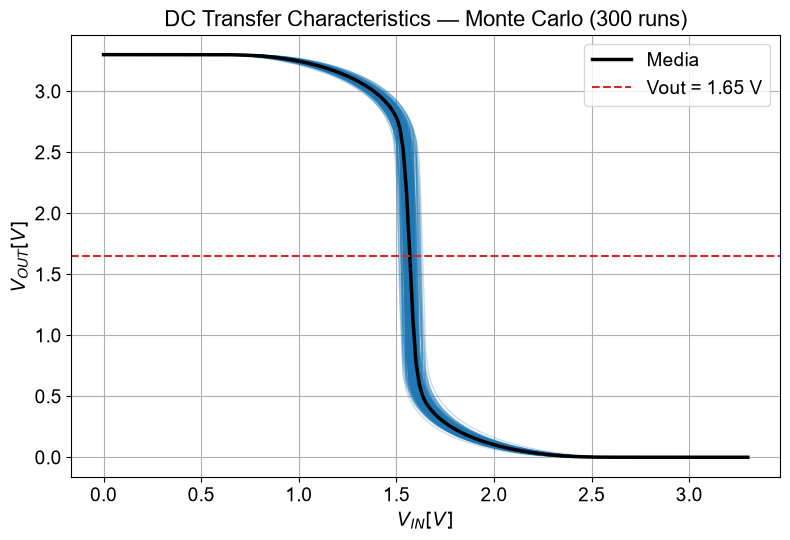

In [29]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for s in range(n_steps):
    ax.plot(x_tr.get_wave(s), vout_tr.get_wave(s), color="tab:blue", alpha=0.25, linewidth=1)

# curva media punto a punto (todas las corridas comparten el mismo eje de V3)
vout_all = np.array([vout_tr.get_wave(s) for s in range(n_steps)])
ax.plot(x_tr.get_wave(0), vout_all.mean(axis=0), color="black", linewidth=2.5, label="Media")
ax.axhline(V_TARGET, color="tab:red", linestyle="--", linewidth=1.5, label=f"Vout = {V_TARGET:.2f} V")

ax.set_title(f"DC Transfer Characteristics — Monte Carlo ({n_steps} runs)", fontsize=16)
ax.set_xlabel(r"$V_{IN} [V]$", fontsize=14)
ax.set_ylabel(r"$V_{OUT} [V]$", fontsize=14)
ax.tick_params(axis="both", labelsize=14)
ax.legend(prop={"size": 14}, loc="upper right")
ax.grid(True)
plt.tight_layout()
plt.show()


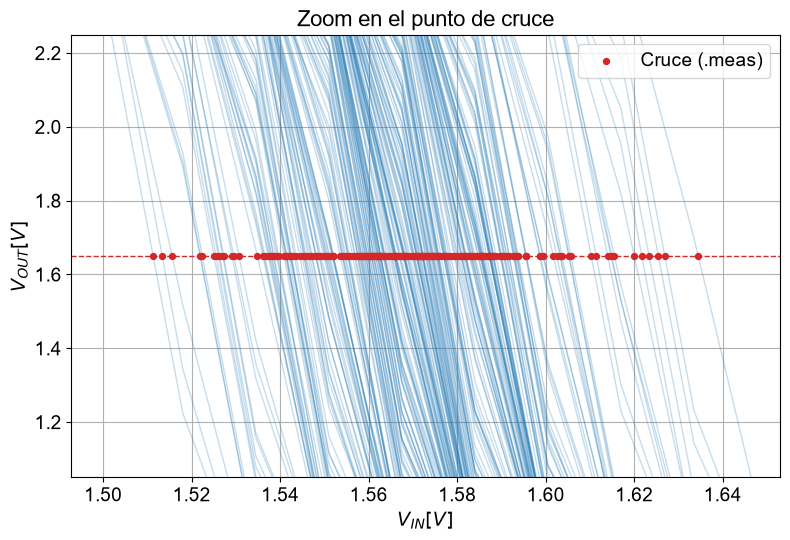

In [30]:
# Zoom a la zona de conmutacion, con el cruce de cada corrida marcado
fig, ax = plt.subplots(figsize=(8, 5.5))
for s in range(n_steps):
    ax.plot(x_tr.get_wave(s), vout_tr.get_wave(s), color="tab:blue", alpha=0.25, linewidth=1)
ax.scatter(df_mc["cross"], np.full(len(df_mc), V_TARGET), s=18, color="tab:red", zorder=3,
           label="Cruce (.meas)")
ax.axhline(V_TARGET, color="tab:red", linestyle="--", linewidth=1)

lo, hi = df_mc["cross"].min(), df_mc["cross"].max()
pad = 0.15 * (hi - lo)
ax.set_xlim(lo - pad, hi + pad)
ax.set_ylim(V_TARGET - 0.6, V_TARGET + 0.6)
ax.set_title("Zoom en el punto de cruce", fontsize=16)
ax.set_xlabel(r"$V_{IN} [V]$", fontsize=14)
ax.set_ylabel(r"$V_{OUT} [V]$", fontsize=14)
ax.tick_params(axis="both", labelsize=14)
ax.legend(prop={"size": 14}, loc="upper right")
ax.grid(True)
plt.tight_layout()
plt.show()


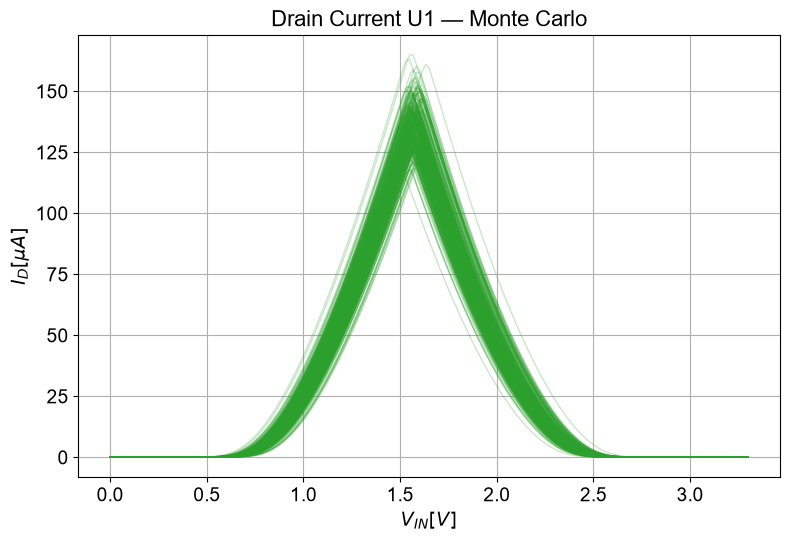

In [31]:
# Corriente de drenador de U1 en todas las corridas (pico = corriente de cortocircuito)
fig, ax = plt.subplots(figsize=(8, 5.5))
for s in range(n_steps):
    ax.plot(x_tr.get_wave(s), id_tr.get_wave(s) * 1e6, color="tab:green", alpha=0.25, linewidth=1)
ax.set_title("Drain Current U1 — Monte Carlo", fontsize=16)
ax.set_xlabel(r"$V_{IN} [V]$", fontsize=14)
ax.set_ylabel(r"$I_{D} [\mu A]$", fontsize=14)
ax.tick_params(axis="both", labelsize=14)
ax.grid(True)
plt.tight_layout()
plt.show()


### 8.2 Estadística de las mediciones (`.db`)
Media, desviación estándar (muestral, `ddof=1`), mínimo/máximo, percentiles, sesgo/curtosis y una prueba de normalidad (Shapiro-Wilk). También el rango ±3σ y el offset respecto a VDD/2 (punto de cruce ideal).

In [32]:
MEAS = "cross"                      # nombre del .meas a analizar (columna del DataFrame)
data = df_mc.loc[df_mc["all_ok"], MEAS].to_numpy()
n    = len(data)

mu, sigma = data.mean(), data.std(ddof=1)
sw_stat, sw_p = stats.shapiro(data)

table = PrettyTable()
table.field_names = ["Métrica", "Valor"]
table.add_row(["Corridas válidas", f"{n} / {len(df_mc)}"])
table.add_row(["Media (μ)", num2eng(mu, precision=3) + "V"])
table.add_row(["Desv. estándar (σ)", num2eng(sigma, precision=3) + "V"])
table.add_row(["σ / μ", f"{100*sigma/mu:.3f} %"])
table.add_row(["Mínimo", num2eng(data.min(), precision=3) + "V"])
table.add_row(["P5 / Mediana / P95", " / ".join(num2eng(p, precision=3) + "V" for p in np.percentile(data, [5, 50, 95]))])
table.add_row(["Máximo", num2eng(data.max(), precision=3) + "V"])
table.add_row(["Rango (max-min)", num2eng(np.ptp(data), precision=3) + "V"])
table.add_row(["μ − 3σ / μ + 3σ", f"{num2eng(mu-3*sigma, precision=3)}V / {num2eng(mu+3*sigma, precision=3)}V"])
table.add_row(["Offset μ − VDD/2", num2eng(mu - V_TARGET, precision=3) + "V"])
table.add_row(["Sesgo (skewness)", f"{stats.skew(data):.3f}"])
table.add_row(["Curtosis (exceso)", f"{stats.kurtosis(data):.3f}"])
table.add_row(["Shapiro-Wilk p-value", f"{sw_p:.3f}  ({'compatible con normal' if sw_p > 0.05 else 'NO normal'})"])
print(f"Estadística de '{MEAS}' — {DB_MC}\n")
print(table)


Estadística de 'cross' — inv_dc_mc.db

+----------------------+--------------------------------+
|       Métrica        |             Valor              |
+----------------------+--------------------------------+
|   Corridas válidas   |           300 / 300            |
|      Media (μ)       |            1.569 V             |
|  Desv. estándar (σ)  |           21.745 mV            |
|        σ / μ         |            1.386 %             |
|        Mínimo        |            1.511 V             |
|  P5 / Mediana / P95  |  1.535 V / 1.569 V / 1.604 V   |
|        Máximo        |            1.634 V             |
|   Rango (max-min)    |           123.173 mV           |
|   μ − 3σ / μ + 3σ    |       1.504 V / 1.634 V        |
|   Offset μ − VDD/2   |           -81.217 mV           |
|   Sesgo (skewness)   |             0.067              |
|  Curtosis (exceso)   |             0.132              |
| Shapiro-Wilk p-value | 0.511  (compatible con normal) |
+----------------------+---------

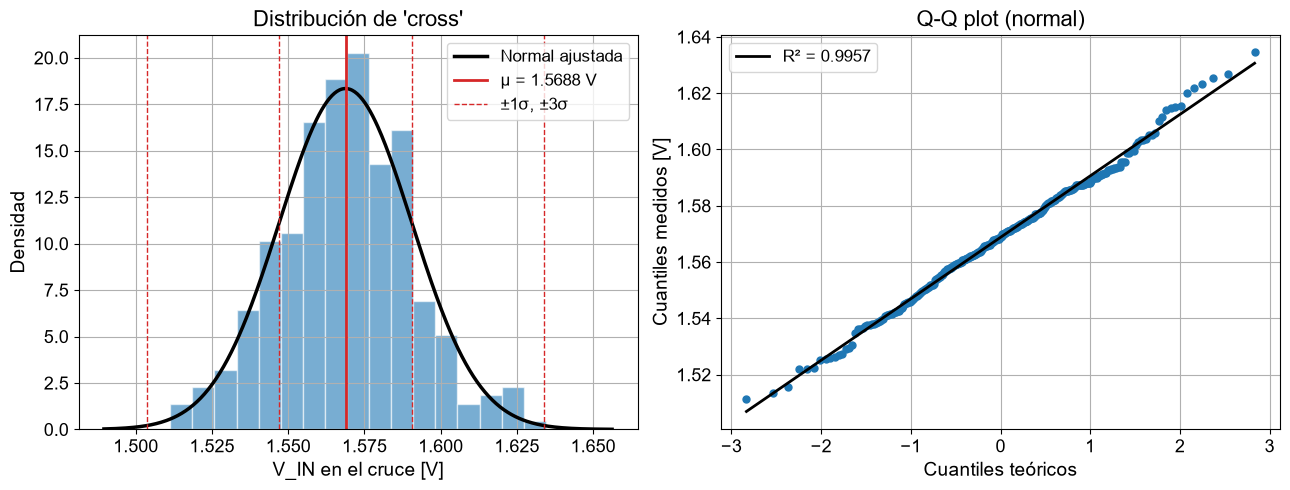

In [33]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# --- Histograma + gaussiana ajustada ---
bins = max(8, int(np.sqrt(n)))
ax1.hist(data, bins=bins, density=True, color="tab:blue", alpha=0.6, edgecolor="white")
xs = np.linspace(data.min() - sigma, data.max() + sigma, 400)
ax1.plot(xs, stats.norm.pdf(xs, mu, sigma), color="black", linewidth=2.5, label="Normal ajustada")
ax1.axvline(mu, color="tab:red", linewidth=2, label=f"μ = {mu:.4f} V")
for k in (-3, -1, 1, 3):
    ax1.axvline(mu + k * sigma, color="tab:red", linestyle="--", linewidth=1,
                label=f"±1σ, ±3σ" if k == -3 else None)
ax1.set_title(f"Distribución de '{MEAS}'", fontsize=16)
ax1.set_xlabel("V_IN en el cruce [V]", fontsize=14)
ax1.set_ylabel("Densidad", fontsize=14)
ax1.tick_params(axis="both", labelsize=13)
ax1.legend(prop={"size": 12})
ax1.grid(True)

# --- Q-Q plot (normalidad) ---
(osm, osr), (slope, intercept, r) = stats.probplot(data, dist="norm")
ax2.plot(osm, osr, "o", color="tab:blue", markersize=5)
ax2.plot(osm, slope * osm + intercept, color="black", linewidth=2, label=f"R² = {r**2:.4f}")
ax2.set_title("Q-Q plot (normal)", fontsize=16)
ax2.set_xlabel("Cuantiles teóricos", fontsize=14)
ax2.set_ylabel("Cuantiles medidos [V]", fontsize=14)
ax2.tick_params(axis="both", labelsize=13)
ax2.legend(prop={"size": 12}, loc="upper left")
ax2.grid(True)

plt.tight_layout()
plt.show()


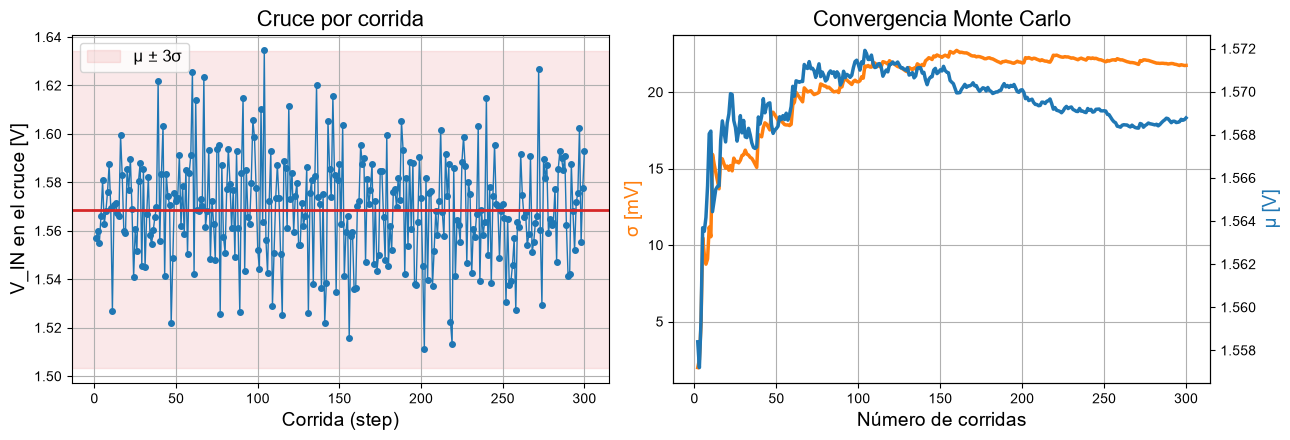

In [34]:
# Valor de la medicion por corrida + convergencia de media/sigma al ir sumando corridas
runs = df_mc.loc[df_mc["all_ok"]].index.to_numpy()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(runs, data, "o-", markersize=4, linewidth=1, color="tab:blue")
ax1.axhline(mu, color="tab:red", linewidth=2)
ax1.axhspan(mu - 3*sigma, mu + 3*sigma, color="tab:red", alpha=0.1, label="μ ± 3σ")
ax1.set_title("Cruce por corrida", fontsize=16)
ax1.set_xlabel("Corrida (step)", fontsize=14)
ax1.set_ylabel("V_IN en el cruce [V]", fontsize=14)
ax1.legend(prop={"size": 12}); ax1.grid(True)

k = np.arange(2, n + 1)
mean_run = np.cumsum(data)[1:] / k
std_run  = np.array([data[:i].std(ddof=1) for i in k])
ax2.plot(k, std_run * 1e3, linewidth=2.5, color="tab:orange", label="σ acumulada [mV]")
ax2.set_xlabel("Número de corridas", fontsize=14)
ax2.set_ylabel("σ [mV]", fontsize=14, color="tab:orange")
ax2.grid(True)
ax3 = ax2.twinx()
ax3.plot(k, mean_run, linewidth=2.5, color="tab:blue", label="μ acumulada [V]")
ax3.set_ylabel("μ [V]", fontsize=14, color="tab:blue")
ax2.set_title("Convergencia Monte Carlo", fontsize=16)
plt.tight_layout()
plt.show()


### 8.3 Correlación con otras métricas (opcional)
Con las curvas del `.raw` se pueden extraer métricas adicionales por corrida (p. ej. ganancia máxima y corriente pico) y ver cuáles se correlacionan con el desplazamiento del cruce.

In [35]:
rows = []
for s in range(n_steps):
    x = x_tr.get_wave(s); y = vout_tr.get_wave(s); i_d = id_tr.get_wave(s)
    g = np.gradient(y, x)
    rows.append({"cross_raw": np.interp(V_TARGET, y[::-1], x[::-1]),   # y decrece con x en un inversor
                 "gain_max": g.min(),                                    # |ganancia| maxima (negativa)
                 "Id_peak [uA]": i_d.max() * 1e6})
df_raw = pd.DataFrame(rows, index=df_mc.index)

df_all = df_mc[[MEAS]].join(df_raw)
print("Chequeo .db vs .raw (max |dif| del cruce): "
      f"{np.abs(df_all[MEAS] - df_all['cross_raw']).max():.2e} V\n")
display(df_all[["cross_raw", "gain_max", "Id_peak [uA]"]].describe().T[["mean", "std", "min", "max"]])
display(df_all[[MEAS, "gain_max", "Id_peak [uA]"]].corr().round(3))


Chequeo .db vs .raw (max |dif| del cruce): 2.03e-08 V



,mean,std,min,max
cross_raw,1.568783,0.021745,1.511296,1.634469
gain_max,-49.620861,2.182263,-54.744362,-43.663521
Id_peak [uA],137.093826,8.965899,115.752464,165.019089


,cross,gain_max,Id_peak [uA]
cross,1.000,0.049,0.164
gain_max,0.049,1.000,0.578
Id_peak [uA],0.164,0.578,1.000
